# Code

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, DBSCAN

print("All imports successful!")

All imports successful!


In [19]:
X, y_true = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=0.8,
    random_state=42
)

print("Dataset shape:", X.shape)

Dataset shape: (300, 2)


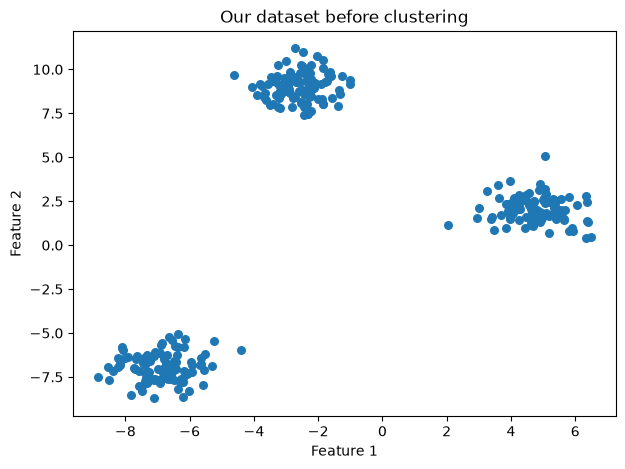

In [20]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 1], s=30)

plt.title("Our dataset before clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

# Clustering
    Clustering is a unsupervised ML technique that groups similar data points together based on their features or similarities. Its goal is to discover patterns and structures in data without needing predefined labels
        Example: Grouping customers based on similar shopping behaviour

Clustering belongs to Unsupervised Learning
-> the computer discovers the group by looking at the data (features)
-> we don't say which data belongs to which group

In [21]:
#Supervised Learning: the computer receives data with the correct label
#Unsupervised Learning: the computer receives data without the correct label

How does the computer decide which data belongs together?
-The computer needs a way to measure how similar two data points are
-one common way is to calculate the distance between them

example: (try as tabelle in code)
costumer   age   sepending

fetaures: the characteristics we use to describe smth
distance: A numerical measure of how far two data points are
centroid: the center of a cluster, often calculated as the average position of its data points

the smaler the distance, the more similar points are according to that distance measure

### **K-Means**


1. You tell the algorithm how many clusters you want. (k=3)
2. It places 3 inital centroids
3. Each data point is assigned to its nearest center
4. The algorithm recalculates the center based on the assigned points
5. It repeats steps 3 & 4 until the groups stop chaning significantly

K-Means needs a specific number of clusters beforhand!

In [22]:
# Creates a K-Means model with 3 clusters.
# random_state ensures reproducible results.
# n_init=10 means K-Means tries 10 different initial centroid positions.

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fits the model to the dataset and assigns each point to a cluster.
cluster_labels = kmeans.fit_predict(X)

# Prints the cluster assignments of the first 20 data points.
print("First 20 cluster labels:")
print(cluster_labels[:20])

First 20 cluster labels:
[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]


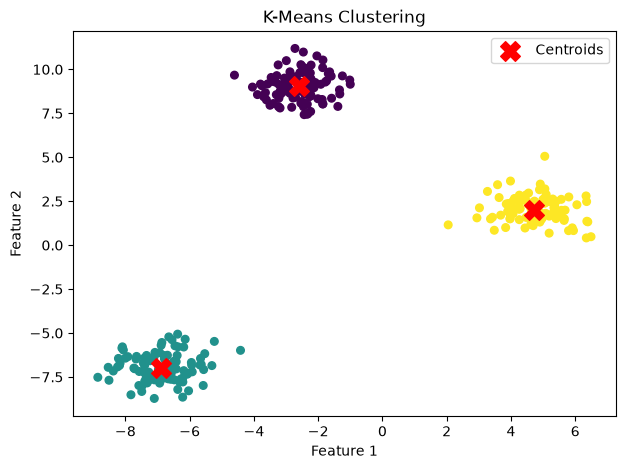

In [23]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=30
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.show()

In [24]:
# Prints the coordinates of the three cluster centers (centroids).
print("Cluster centers:")
print(kmeans.cluster_centers_)

# Inertia measures how close the data points are to their assigned centroids.
# Lower inertia generally means more compact clusters.
print("\nInertia:")
print(kmeans.inertia_)

Cluster centers:
[[-2.60842567  9.03771305]
 [-6.88302287 -6.96320924]
 [ 4.72565847  2.00310936]]

Inertia:
362.7901127196244


### **DBSCAN**

DBSCAN looks for areas where many data points are close together

Example: People standing at a concert
- A large group of people standing close together forms a cluster
- Another group standing close together forms another cluster
- A person standing far away from everyone else might be considered noise

=> it discovers clusters based on densityt, you don't have to speficy the number of clusters, it can idenify unsual points (noise), it can discover clusters with irregular shapes

In [25]:
# Creates a DBSCAN model.
# eps defines the maximum neighbourhood distance.
# min_samples defines the minimum number of points needed for a dense region.

dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

# Fits DBSCAN to the dataset and assigns cluster labels.
dbscan_labels = dbscan.fit_predict(X)

# Prints the cluster assignments of the first 20 data points.
print("First 20 DBSCAN labels:")
print(dbscan_labels[:20])

First 20 DBSCAN labels:
[0 0 1 2 0 2 1 2 1 1 1 2 1 1 0 1 0 2 1 1]


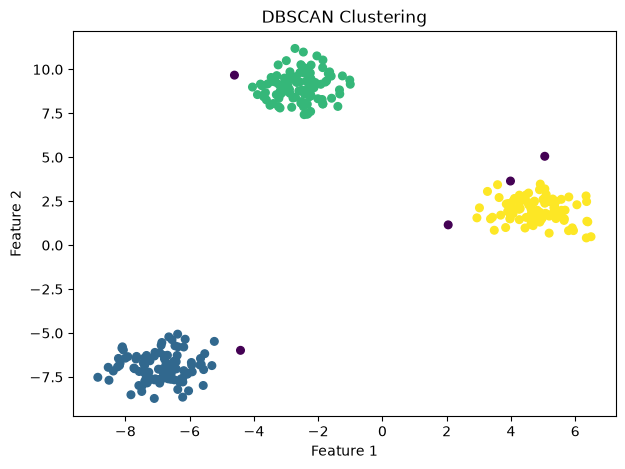

In [26]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=30
)

plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [27]:
# Finds all unique cluster labels and counts their occurrences.
unique_labels, counts = np.unique(dbscan_labels, return_counts=True)

# Goes through each cluster label and its corresponding number of points.
for label, count in zip(unique_labels, counts):

    # Label -1 represents noise points or outliers.
    if label == -1:
        print(f"Noise points: {count}")

    # All other labels represent detected clusters.
    else:
        print(f"Cluster {label}: {count} points")

Noise points: 5
Cluster 0: 99 points
Cluster 1: 99 points
Cluster 2: 97 points


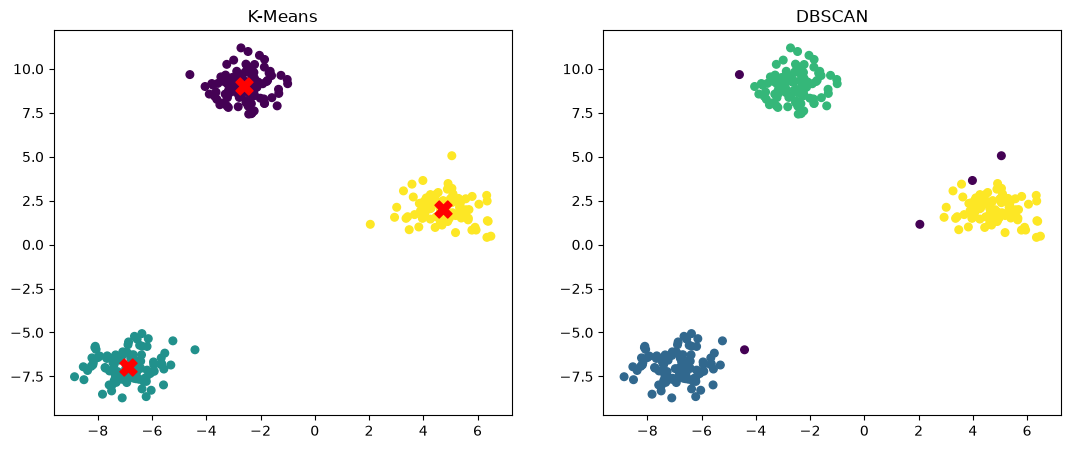

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# K-Means
axes[0].scatter(
    X[:, 0], X[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=30
)
axes[0].scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=150
)
axes[0].set_title("K-Means")

# DBSCAN
axes[1].scatter(
    X[:, 0], X[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=30
)
axes[1].set_title("DBSCAN")

plt.show()

### **Agglomerative Clustering**
(=Hiearachial Clustering)


Initally, each point has its own cluster. Then
1. The two closest points are combined
2. The next closest point or groups are combined
3. This continues until the desired number of clusters is reached

=> This algorithm uses a bottom up approach

In [29]:
# Imports the Agglomerative Clustering algorithm.
from sklearn.cluster import AgglomerativeClustering

# Creates a model that identifies 3 clusters.
# linkage="ward" merges groups while minimising the increase in within-cluster variation.
agg = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Fits the model and assigns each data point to a cluster.
agg_labels = agg.fit_predict(X)

# Prints the cluster assignments of the first 20 data points.
print("First 20 Agglomerative labels:")
print(agg_labels[:20])

First 20 Agglomerative labels:
[0 0 2 1 0 1 2 1 2 2 2 1 2 2 0 2 0 1 2 2]


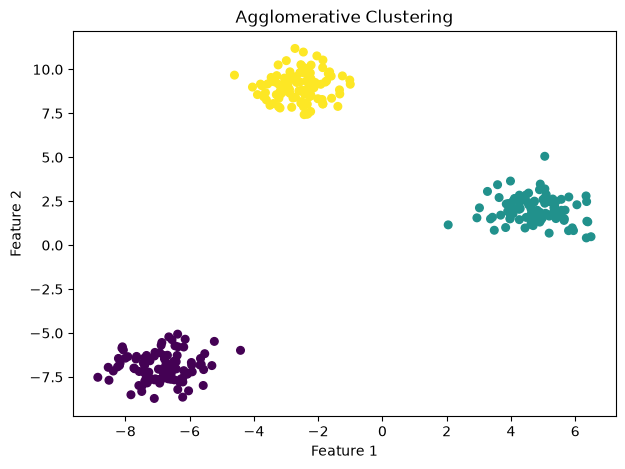

In [30]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=agg_labels,
    cmap="viridis",
    s=30
)

plt.title("Agglomerative Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

### **HDBSCAN (related to DBSCAN)**


it also searches for dense regions in the data, but handels different density levels more flexibly

Lets day:
One cluster has many points very close together and another cluster has point more spread out
DBSCAN can struggle when clusters have different densities. HDBSCAN is designed to handle this situation better

In [31]:
# Creates an HDBSCAN model.
# min_cluster_size defines the minimum size of a cluster.
# min_samples controls how strictly dense regions are identified.

hdbscan = HDBSCAN(
    min_cluster_size=5,
    min_samples=5,
    copy=False
)

# Fits HDBSCAN to the dataset and assigns cluster labels.
hdbscan_labels = hdbscan.fit_predict(X)

# Prints the cluster assignments of the first 20 data points.
print("First 20 HDBSCAN labels:")
print(hdbscan_labels[:20])

First 20 HDBSCAN labels:
[0 0 2 1 0 1 2 1 2 2 2 1 2 2 0 2 0 1 2 2]


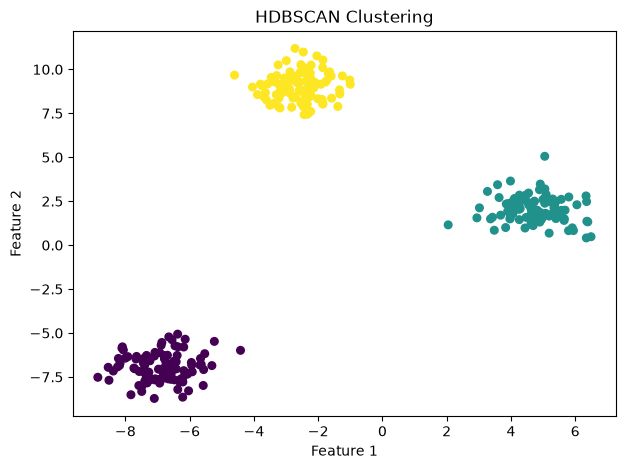

In [32]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=hdbscan_labels,
    cmap="viridis",
    s=30
)

plt.title("HDBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

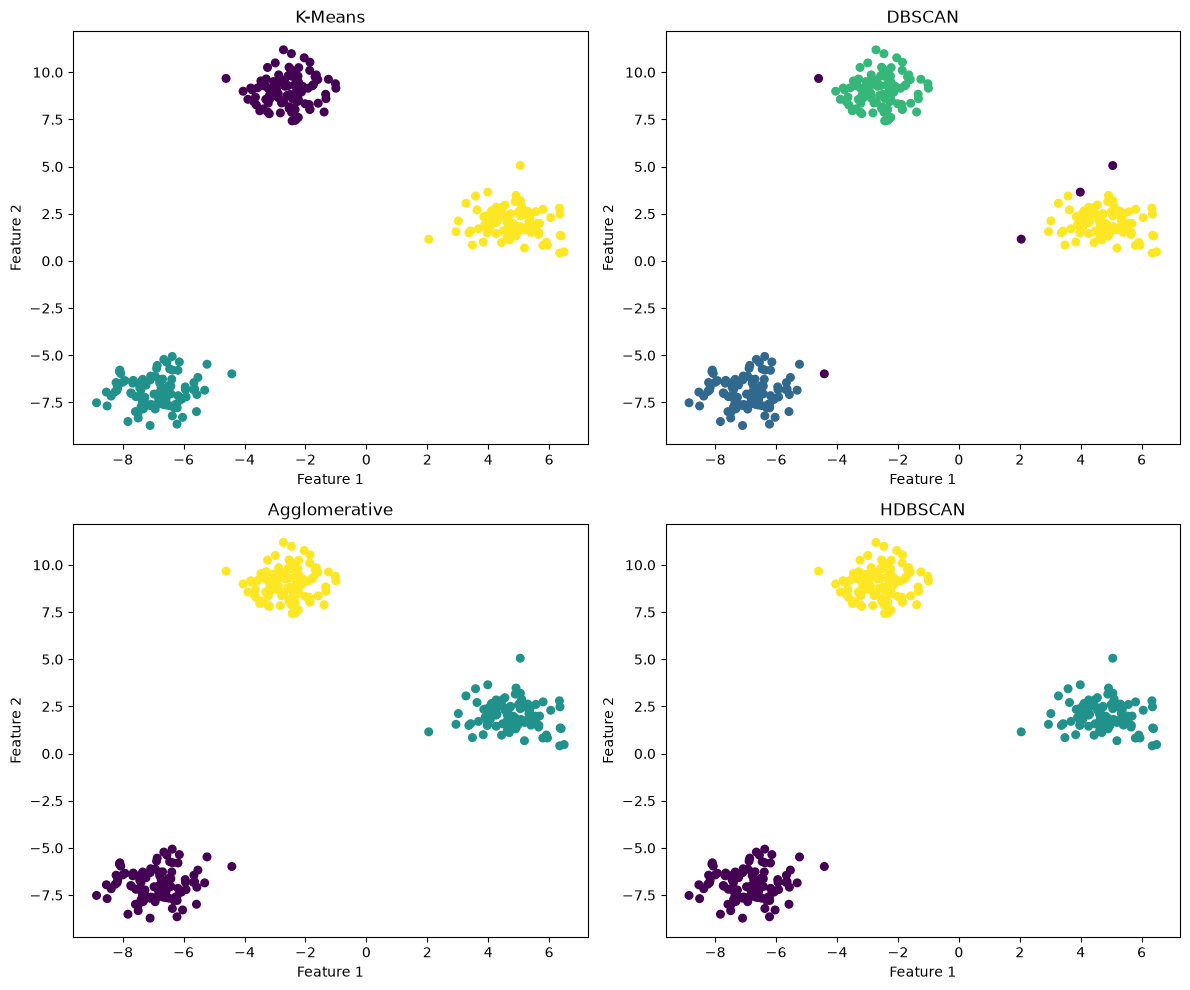

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

results = [
    ("K-Means", cluster_labels),
    ("DBSCAN", dbscan_labels),
    ("Agglomerative", agg_labels),
    ("HDBSCAN", hdbscan_labels)
]

for ax, (name, labels) in zip(axes.flat, results):
    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap="viridis",
        s=30
    )

    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

When should we use which algorithm?

You know how many groups we need?
Y: try K-Means
N: Consider DBSCAN or HDBSCAN

You wanna build a hierachy of groups?
Try Agglomerative Clustering

Do you have cluster with different densities?
HDBSCAN

Do you have lots of data and want a faster K-Means variant?
Consider MiniBatchMeans

1. Clustering does not automatically know what the groups mean.
For example, K-Means might produce three clusters numbered 0, 1 and 2.
It doesn't know that these groups represent "low-spending", "medium-spending" and "high-spending" customers.
You have to interpret the results.

2. More clusters don't necessarily mean better results.
If you choose K-Means with 10 clusters, the algorithm will try to create 10 clusters, even if 3 would have been more meaningful.

3. Clustering depends on the features you choose.
If you group customers using age and spending, you might get different results than if you use age and number of purchases.

4. Scaling matters.
If one feature has much larger numerical values than another, it can dominate the distance calculation.

5. Clustering is not classification.
Classification predicts predefined categories. Clustering discovers groups without predefined categories.

Cluster Algorithms: 
KMeans, DBSCAN, HDBSCAN, AgglomerativeClustering, AffinityPropagation, Birch, BisectingKMeans, MeanShift, MiniBatchKMeans, OPTICS, SpectralClustering

# Research paper 170

The paper investigates AL and how well different AL methods perform across different types of datasets

Author discovered 3 important problems
1. **Different experiments were difficult to compare**

    If two people each use a different data set, model and setting, both would claim their algorithm works better. We can't compre their results bc they didn't conduct the same experiment


2. **too few repetitions**

    let's say we test an algorithm three times and the average accuracy is 86.7%. Would the average be different if we've tested the algorithm 50 times?
    It depends on the random seed and the particular runs
    => three repitions are not enogh to make reliable conclusion about an algorithm's performance


3. **research focused too much on indiviual data domains**

    AL methods should be tested across different kinds of data -> just because an algorithm works well with pictures doesnt mean that it will also work good on text or numerical datasets

**CDALBench = Cross Domain Active Learning Benchmark**

Is a benchmark designed to evaluate AL methods across different domains

*a benchmark is a standardised testing environment that allows different methods to be compared under similar conditions*

The important idea is that AL methods should not be tested on one type of dataset. They should be evaluated across different data features and domains

Investigated AL methods
    Coreset
        focuses on selecting representative & diverse data points => cover data distribution as well as possible
    TypiClust
        uses clustering to identify groups of similr data points
    BADGE
        combines uncertainty (selecting point about which the model is unsure) & diversity (selecting points that are different from one another)

conclution = there is no single Active learning method that performs best on every dataset

important properties that can overlap but are not the same:
    Representative; A data point that describes a group of similar data points
    Informative; A data point that helps the model learn smth useful

# Zusammenhang

CDALBench connects to clustering by evaluating AL methods that use clustering to select representative and diverse data points. Clustering identifies groups in unlabelled data, while AL selects which point should be labelled. CDLABench compares these methods across different data domains and show that clustering can be useful, but its effectivness depends on the dataset

*Clustering helps us understand the structure of unlabelled data and AL uses unlabelled data to decide which samples should be labelled next.
The paper shows how clustering can be used as part of AL and looks into situation in which clustering based selection doesn't work good.*